# GNN 266 — Plaintiff vs Defendant Patent Embedding

**Task**: co_litigation link prediction (pp → dp)  
**Graph**: patent / company / ipc / case (hetero)  
**Model A**: Single-task HeteroSAGE (phase3 style)  
**Model B**: Multi-task HeteroSAGE + IPC Jaccard + citation hop regression  
**Unique advantage**: both plaintiff AND defendant patents are known (266 actual cases)

In [2]:
# Cell 1 — Imports
import subprocess, sys, re, warnings
from pathlib import Path
from collections import defaultdict

def _ensure(*pkgs):
    for pkg in pkgs:
        try:
            __import__(pkg.split('[')[0].replace('-','_'))
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

_ensure('numpy', 'pandas', 'networkx', 'faiss-cpu', 'scikit-learn', 'matplotlib')

import numpy as np
import pandas as pd
import networkx as nx
import faiss
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, average_precision_score

try:
    import torch_geometric
    from torch_geometric.data import HeteroData
    from torch_geometric.nn import HeteroConv, SAGEConv
    import torch_geometric.transforms as T
    print('PyG OK:', torch_geometric.__version__)
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch_geometric', '-q'])
    import torch_geometric
    from torch_geometric.data import HeteroData
    from torch_geometric.nn import HeteroConv, SAGEConv
    import torch_geometric.transforms as T
    print('PyG installed:', torch_geometric.__version__)

warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'PyTorch: {torch.__version__}')

PyG OK: 2.8.0
Device: cuda
PyTorch: 2.6.0+cu124


In [3]:
# Cell 2 — Paths
ROOT  = Path('../..').resolve()
SRC   = ROOT / 'src'
DATA  = ROOT / 'data' / 'samples'

FAISS_INDEX = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/faiss.index')
PATENT_IDX  = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/patent_index.parquet')

print('ROOT :', ROOT)
print('FAISS:', FAISS_INDEX.exists())

ROOT : /home2/jmbyeon/developments/tf_litigation/MANTF-master
FAISS: True


In [4]:
# Cell 3 — Data loading (company normalization + raw data)
_SUFFIX = re.compile(
    r',?\s*('
    r'incorporated|corporation|company|limited liability company'
    r'|limited liability partnership|limited partnership|limited'
    r'|inc|corp|co|ltd|llc|llp|lp|plc|gmbh|b\.?v|n\.?v|s\.?a|a\.?g|s\.?r\.?l'
    r'|pvt|pte|pty|ab|as|a\/s|oy|oyj|spa|srl|sarl|sas|bv|nv'
    r'|an? (?:delaware|california|new\s+york|new\s+jersey|texas|illinois|florida'
    r'|washington|ohio|michigan|minnesota|pennsylvania|nevada|maryland|virginia'
    r'|massachusetts|colorado|georgia|indiana|wisconsin|arizona|connecticut'
    r'|netherlands|korean?|japanese|german|french|canadian|british|swedish|swiss)'
    r'\s+(?:corporation|limited\s+liability(?:\s+company)?|limited\s+partnership|limited|company)'
    r'|doing business as|terminated.*'
    r')[,.]?\s*$',
    re.IGNORECASE
)
_PREFIX = re.compile(r'^(the|a|an)\s+', re.IGNORECASE)
_JUNK   = re.compile(r'^(does |john doe|unknown|xyz |consolidated civil|consolidating civil|et al)', re.IGNORECASE)

def deep_normalize(name):
    s = str(name).strip().replace('&', 'and')
    s = re.sub(r'[^\w\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip().upper()
    for _ in range(6):
        new = _SUFFIX.sub('', s, count=1).strip()
        if new == s: break
        s = new
    return _PREFIX.sub('', s).strip()

_mm_path = DATA / 'company_merge_map.csv'
MERGE_MAP = {}
if _mm_path.exists():
    _mm = pd.read_csv(_mm_path)
    MERGE_MAP = dict(zip(_mm['from'], _mm['to']))

def canonical(name):
    n = deep_normalize(name)
    return MERGE_MAP.get(n, n)

def parse_pipe(s):
    if pd.isna(s): return []
    return [x.strip() for x in str(s).split('|') if x.strip()]

raw = pd.read_csv(DATA / 'both_side_patents.csv')

rows = []
for _, r in raw.iterrows():
    for pat in parse_pipe(r['P_patents']):
        rows.append({'case_row_id': r['case_row_id'], 'patent_id': pat, 'side': 'plaintiff'})
    for pat in parse_pipe(r['D_patents']):
        rows.append({'case_row_id': r['case_row_id'], 'patent_id': pat, 'side': 'defendant'})
df_pats = pd.DataFrame(rows)
ALL_PATENTS = set(df_pats['patent_id'].unique())

company_rows = []
for _, r in raw.iterrows():
    for name in parse_pipe(r['plaintiffs']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': r['case_row_id'], 'norm_name': cn, 'side': 'plaintiff'})
    for name in parse_pipe(r['defendants']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': r['case_row_id'], 'norm_name': cn, 'side': 'defendant'})
df_companies = pd.DataFrame(company_rows)

case_rows = []
for case_id, grp in df_companies.groupby('case_row_id'):
    p = grp[grp['side']=='plaintiff']['norm_name'].tolist()
    d = grp[grp['side']=='defendant']['norm_name'].tolist()
    case_rows.append({'case_row_id': case_id,
                      'main_plaintiff': p[0] if p else None,
                      'main_defendant': d[0] if d else None})
df_cases = pd.DataFrame(case_rows)
litigation_companies = set(df_companies['norm_name'])

print(f'Patents: {len(ALL_PATENTS)}, Companies: {len(litigation_companies)}, Cases: {len(df_cases)}')

Patents: 1331, Companies: 1061, Cases: 269


In [5]:
# Cell 4 — IPC / Citation / Assignee load
ipc_raw = pd.read_csv(SRC / 'g_ipc_at_issue.tsv', sep='\t',
                      usecols=['patent_id','section','ipc_class','subclass'], dtype=str)
ipc_raw['patent_id'] = ipc_raw['patent_id'].str.strip()
df_ipc = ipc_raw[ipc_raw['patent_id'].isin(ALL_PATENTS)].copy()
df_ipc['ipc_code'] = (df_ipc['section'].fillna('') +
                      df_ipc['ipc_class'].fillna('') +
                      df_ipc['subclass'].fillna('')).str.strip()
df_ipc = df_ipc[df_ipc['ipc_code'] != ''].drop_duplicates(['patent_id','ipc_code'])

cit_raw = pd.read_csv(SRC / 'g_us_patent_citation.tsv', sep='\t',
                      usecols=['patent_id','citation_patent_id'], dtype=str)
cit_raw['patent_id']          = cit_raw['patent_id'].str.strip()
cit_raw['citation_patent_id'] = cit_raw['citation_patent_id'].str.strip()
df_cit_internal = cit_raw[
    cit_raw['patent_id'].isin(ALL_PATENTS) &
    cit_raw['citation_patent_id'].isin(ALL_PATENTS)
].drop_duplicates().copy()

own_raw = pd.read_csv(DATA / 'patent_ownership_matched_4.csv',
                      usecols=['patent_norm','final_owner'], dtype=str).dropna()
own_raw['org_norm'] = own_raw['final_owner'].apply(canonical)
df_asgn = own_raw[own_raw['patent_norm'].isin(ALL_PATENTS) &
                  (own_raw['org_norm'].str.len() > 2)].drop_duplicates(
    ['patent_norm','org_norm']
).rename(columns={'patent_norm':'patent_id'})[['patent_id','org_norm']]

print(f'IPC codes: {df_ipc["ipc_code"].nunique()}')
print(f'Internal citations: {len(df_cit_internal)}')
print(f'Ownership pairs: {len(df_asgn)}')

IPC codes: 218
Internal citations: 803
Ownership pairs: 1396


In [6]:
# Cell 5 — FAISS embedding load
_index   = faiss.read_index(str(FAISS_INDEX))
_pidx    = pd.read_parquet(PATENT_IDX)
pid_to_fid = dict(zip(_pidx['patent_id'].astype(str).str.strip(), _pidx['faiss_id']))

pat_list   = sorted(ALL_PATENTS)
pat_to_idx = {p: i for i, p in enumerate(pat_list)}

FAISS_DIM = 1024
pat_emb   = np.zeros((len(pat_list), FAISS_DIM), dtype=np.float32)
covered   = 0
for i, pid in enumerate(pat_list):
    if pid in pid_to_fid:
        pat_emb[i] = _index.reconstruct(int(pid_to_fid[pid]))
        covered += 1

print(f'Patent embeddings: {covered}/{len(pat_list)} covered ({covered/len(pat_list)*100:.1f}%)')
print(f'Shape: {pat_emb.shape}')

Patent embeddings: 1331/1331 covered (100.0%)
Shape: (1331, 1024)


In [7]:
# Cell 7 — Co-litigation pairs + case-level train/val/test split
coliti_src, coliti_dst, coliti_case = [], [], []
for case_id, grp in df_pats.groupby('case_row_id'):
    p_pats = grp[grp['side']=='plaintiff']['patent_id'].tolist()
    d_pats = grp[grp['side']=='defendant']['patent_id'].tolist()
    for pp in p_pats:
        for dp in d_pats:
            if pp in pat_to_idx and dp in pat_to_idx:
                coliti_src.append(pat_to_idx[pp])
                coliti_dst.append(pat_to_idx[dp])
                coliti_case.append(case_id)

coliti_edges = torch.tensor([coliti_src, coliti_dst], dtype=torch.long)
coliti_cases = np.array(coliti_case)
print(f'Total co_litigation pairs (P→D): {coliti_edges.shape[1]}')

# Case-level split (no pair-level leakage)
rng = np.random.default_rng(42)
all_case_ids = np.array(sorted(raw['case_row_id'].unique()))
rng.shuffle(all_case_ids)
n = len(all_case_ids)
train_cases = set(all_case_ids[:int(n*0.8)])
val_cases   = set(all_case_ids[int(n*0.8):int(n*0.9)])
test_cases  = set(all_case_ids[int(n*0.9):])

tr_mask = np.array([c in train_cases for c in coliti_case])
va_mask = np.array([c in val_cases   for c in coliti_case])
te_mask = np.array([c in test_cases  for c in coliti_case])

train_edges = coliti_edges[:, tr_mask]
val_edges   = coliti_edges[:, va_mask]
test_edges  = coliti_edges[:, te_mask]

print(f'Train cases: {len(train_cases)} → {train_edges.shape[1]} pairs')
print(f'Val   cases: {len(val_cases)}   → {val_edges.shape[1]} pairs')
print(f'Test  cases: {len(test_cases)}  → {test_edges.shape[1]} pairs')

Total co_litigation pairs (P→D): 2508
Train cases: 215 → 2198 pairs
Val   cases: 27   → 145 pairs
Test  cases: 27  → 165 pairs


In [8]:
# Cell 6 — PyG HeteroData construction (leakage-free)
# Must run after Cell 7 (split) so train_val_cases is defined
co_list   = sorted(litigation_companies)
co_to_idx = {c: i for i, c in enumerate(co_list)}

ipc_list   = sorted(df_ipc['ipc_code'].unique())
ipc_to_idx = {ipc: i for i, ipc in enumerate(ipc_list)}

case_list   = sorted(raw['case_row_id'].unique())
case_to_idx = {c: i for i, c in enumerate(case_list)}

data = HeteroData()

data['patent'].x          = torch.tensor(pat_emb, dtype=torch.float32)
data['company'].num_nodes = len(co_list)
data['ipc'].num_nodes     = len(ipc_list)
data['case'].num_nodes    = len(case_list)

def make_edge(src_ids, dst_ids):
    return torch.tensor([src_ids, dst_ids], dtype=torch.long)

# IPC: all patents, no leakage
p_src, i_dst = [], []
for _, r in df_ipc.iterrows():
    if r['patent_id'] in pat_to_idx and r['ipc_code'] in ipc_to_idx:
        p_src.append(pat_to_idx[r['patent_id']])
        i_dst.append(ipc_to_idx[r['ipc_code']])
data['patent','has_ipc','ipc'].edge_index     = make_edge(p_src, i_dst)
data['ipc','rev_has_ipc','patent'].edge_index = make_edge(i_dst, p_src)

# Citations: all internal, no leakage
cs, cd = [], []
for _, r in df_cit_internal.iterrows():
    if r['patent_id'] in pat_to_idx and r['citation_patent_id'] in pat_to_idx:
        cs.append(pat_to_idx[r['patent_id']])
        cd.append(pat_to_idx[r['citation_patent_id']])
data['patent','cites','patent'].edge_index    = make_edge(cs, cd)
data['patent','cited_by','patent'].edge_index = make_edge(cd, cs)

# Ownership: all, no leakage
co_s, p_d = [], []
for _, r in df_asgn.iterrows():
    if r['org_norm'] in co_to_idx and r['patent_id'] in pat_to_idx:
        co_s.append(co_to_idx[r['org_norm']])
        p_d.append(pat_to_idx[r['patent_id']])
data['company','owns','patent'].edge_index     = make_edge(co_s, p_d)
data['patent','owned_by','company'].edge_index = make_edge(p_d, co_s)

# asserted_in: train+val only — test case relay edges hidden to prevent leakage
train_val_cases = train_cases | val_cases
p_src, c_dst = [], []
for _, r in df_pats.iterrows():
    if r['case_row_id'] not in train_val_cases:
        continue
    if r['patent_id'] in pat_to_idx and r['case_row_id'] in case_to_idx:
        p_src.append(pat_to_idx[r['patent_id']])
        c_dst.append(case_to_idx[r['case_row_id']])
data['patent','asserted_in','case'].edge_index     = make_edge(p_src, c_dst)
data['case','rev_asserted_in','patent'].edge_index = make_edge(c_dst, p_src)

# company sued: train+val only
co_s2, co_d2 = [], []
for _, r in df_cases.iterrows():
    if r['case_row_id'] not in train_val_cases:
        continue
    if r['main_plaintiff'] and r['main_defendant']:
        if r['main_plaintiff'] in co_to_idx and r['main_defendant'] in co_to_idx:
            co_s2.append(co_to_idx[r['main_plaintiff']])
            co_d2.append(co_to_idx[r['main_defendant']])
data['company','sued','company'].edge_index = make_edge(co_s2, co_d2)

print(data)
print()
for et, ei in data.edge_index_dict.items():
    print(f'  {str(et):<45} {ei.shape[1]:>8} edges')
print(f'\n  asserted_in / sued: test {len(test_cases)} cases excluded → no leakage')

HeteroData(
  patent={ x=[1331, 1024] },
  company={ num_nodes=1061 },
  ipc={ num_nodes=218 },
  case={ num_nodes=269 },
  (patent, has_ipc, ipc)={ edge_index=[2, 1545] },
  (ipc, rev_has_ipc, patent)={ edge_index=[2, 1545] },
  (patent, cites, patent)={ edge_index=[2, 803] },
  (patent, cited_by, patent)={ edge_index=[2, 803] },
  (company, owns, patent)={ edge_index=[2, 1370] },
  (patent, owned_by, company)={ edge_index=[2, 1370] },
  (patent, asserted_in, case)={ edge_index=[2, 1340] },
  (case, rev_asserted_in, patent)={ edge_index=[2, 1340] },
  (company, sued, company)={ edge_index=[2, 242] }
)

  ('patent', 'has_ipc', 'ipc')                      1545 edges
  ('ipc', 'rev_has_ipc', 'patent')                  1545 edges
  ('patent', 'cites', 'patent')                      803 edges
  ('patent', 'cited_by', 'patent')                   803 edges
  ('company', 'owns', 'patent')                     1370 edges
  ('patent', 'owned_by', 'company')                 1370 edges
  ('patent'

In [9]:
# Cell 8 — Pair-level auxiliary targets (for Model B)
# IPC Jaccard per (pp, dp) pair
ipc_by_pat = df_ipc.groupby('patent_id')['ipc_code'].apply(set).to_dict()

def pair_jaccard(pp, dp):
    s1 = ipc_by_pat.get(pp, set())
    s2 = ipc_by_pat.get(dp, set())
    if not s1 or not s2: return 0.0
    inter = len(s1 & s2)
    union = len(s1 | s2)
    return inter / union if union else 0.0

# Citation hop → normalized score (1-hop=1.0, 2-hop=0.5, 3-hop=0.25, none=0.0)
G_cit = nx.DiGraph()
G_cit.add_nodes_from(ALL_PATENTS)
for _, r in df_cit_internal.iterrows():
    G_cit.add_edge(r['patent_id'], r['citation_patent_id'])

HOP_SCORE = {1: 1.0, 2: 0.5, 3: 0.25}

def pair_cit_score(pp, dp):
    for src, tgt in [(pp, dp), (dp, pp)]:
        try:
            lengths = nx.single_source_shortest_path_length(G_cit, src, cutoff=3)
            if tgt in lengths:
                return HOP_SCORE.get(lengths[tgt], 0.0)
        except nx.NodeNotFound:
            pass
    return 0.0

# Compute for all training pairs
print('Computing auxiliary targets for training pairs...')
idx_to_pid = {v: k for k, v in pat_to_idx.items()}

def compute_aux(edges):
    jaccards, cit_scores = [], []
    for i in range(edges.shape[1]):
        pp = idx_to_pid[edges[0, i].item()]
        dp = idx_to_pid[edges[1, i].item()]
        jaccards.append(pair_jaccard(pp, dp))
        cit_scores.append(pair_cit_score(pp, dp))
    return torch.tensor(jaccards, dtype=torch.float32), \
           torch.tensor(cit_scores, dtype=torch.float32)

train_jaccard, train_cit = compute_aux(train_edges)
print(f'IPC Jaccard  — mean: {train_jaccard.mean():.3f}, non-zero: {(train_jaccard>0).sum().item()}')
print(f'Citation score — mean: {train_cit.mean():.3f}, non-zero: {(train_cit>0).sum().item()}')

Computing auxiliary targets for training pairs...
IPC Jaccard  — mean: 0.383, non-zero: 990
Citation score — mean: 0.134, non-zero: 303


In [10]:
# Cell 9 — FAISS cosine similarity baseline
from numpy.linalg import norm

def faiss_baseline_auc(edges, n_neg=None):
    src_e = pat_emb[edges[0].numpy()]
    dst_e = pat_emb[edges[1].numpy()]
    pos   = (src_e * dst_e).sum(1)  # L2-normalized → dot = cosine

    n = len(pos)
    if n_neg is None: n_neg = n
    rng2   = np.random.default_rng(99)
    neg_idx = rng2.integers(0, len(pat_list), size=n_neg)
    neg_e  = pat_emb[neg_idx]
    neg    = (src_e[:n_neg] * neg_e).sum(1)

    scores = np.concatenate([pos, neg])
    labels = np.array([1]*n + [0]*n_neg)
    return roc_auc_score(labels, scores), average_precision_score(labels, scores)

for split, edges in [('val', val_edges), ('test', test_edges)]:
    auroc, auprc = faiss_baseline_auc(edges)
    print(f'FAISS baseline [{split}]  AUROC={auroc:.4f}  AUPRC={auprc:.4f}')

FAISS baseline [val]  AUROC=0.8066  AUPRC=0.8231
FAISS baseline [test]  AUROC=0.9300  AUPRC=0.8960


In [11]:
# Cell 10 — Model definition (shared backbone)
N_COMPANIES = len(co_list)
N_IPC       = len(ipc_list)
N_CASES     = len(case_list)
HIDDEN_DIM  = 256
OUT_DIM     = 128
N_LAYERS    = 3

EDGE_TYPES = [
    ('patent',  'cites',           'patent'),
    ('patent',  'cited_by',        'patent'),
    ('patent',  'has_ipc',         'ipc'),
    ('ipc',     'rev_has_ipc',     'patent'),
    ('patent',  'asserted_in',     'case'),
    ('case',    'rev_asserted_in', 'patent'),
    ('company', 'owns',            'patent'),
    ('patent',  'owned_by',        'company'),
    ('company', 'sued',            'company'),
]


class HeteroGNN(nn.Module):
    def __init__(self, pat_dim, n_co, n_ipc, n_case,
                 hidden=HIDDEN_DIM, out=OUT_DIM, n_layers=N_LAYERS, drop=0.2):
        super().__init__()
        # Input projections
        self.pat_proj  = nn.Sequential(nn.Linear(pat_dim, hidden), nn.ReLU())
        self.co_emb    = nn.Embedding(n_co,   hidden)
        self.ipc_emb   = nn.Embedding(n_ipc,  hidden)
        self.case_emb  = nn.Embedding(n_case, hidden)

        # SAGEConv layers
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            conv = HeteroConv({
                et: SAGEConv(hidden, hidden, normalize=True)
                for et in EDGE_TYPES
            }, aggr='mean')
            self.convs.append(conv)
            self.bns.append(nn.ModuleDict({
                nt: nn.BatchNorm1d(hidden)
                for nt in ['patent','company','ipc','case']
            }))

        self.out_proj = nn.Linear(hidden, out)
        self.drop     = nn.Dropout(drop)

    def _init_x(self):
        return {
            'patent':  self.pat_proj(data.to(device)['patent'].x),
            'company': self.co_emb.weight,
            'ipc':     self.ipc_emb.weight,
            'case':    self.case_emb.weight,
        }

    def forward(self, hetero_data):
        x = {
            'patent':  self.pat_proj(hetero_data['patent'].x),
            'company': self.co_emb.weight,
            'ipc':     self.ipc_emb.weight,
            'case':    self.case_emb.weight,
        }
        edge_idx = hetero_data.edge_index_dict
        for conv, bn in zip(self.convs, self.bns):
            x = conv(x, edge_idx)
            x = {k: self.drop(F.relu(bn[k](v))) if k in bn else self.drop(F.relu(v))
                 for k, v in x.items()}
        return {k: self.out_proj(v) for k, v in x.items()}


print('HeteroGNN defined')
print(f'  Relay embeddings: company({N_COMPANIES}), ipc({N_IPC}), case({N_CASES})')

HeteroGNN defined
  Relay embeddings: company(1061), ipc(218), case(269)


In [12]:
# Cell 11 — Training utilities
def hard_neg_sample(pos_edges, k=1, seed=None):
    rng_n = np.random.default_rng(seed)
    n = pos_edges.shape[1]
    neg_dst = torch.tensor(
        rng_n.integers(0, len(pat_list), size=n * k), dtype=torch.long
    )
    neg_src = pos_edges[0].repeat(k)
    return torch.stack([neg_src, neg_dst])


def margin_loss(h_pat, pos_edges, neg_edges):
    ps = F.cosine_similarity(h_pat[pos_edges[0]], h_pat[pos_edges[1]])
    ns = F.cosine_similarity(h_pat[neg_edges[0]], h_pat[neg_edges[1]])
    n  = ps.shape[0]
    return F.relu(1 - ps.unsqueeze(1) + ns.view(n, -1)).mean()


def multitask_loss(h_pat, pos_edges, neg_edges,
                   ipc_jac, cit_score, lam1=0.1, lam2=0.05):
    l_link = margin_loss(h_pat, pos_edges, neg_edges)

    # Auxiliary losses: only on pairs with non-zero signal (avoid pushing everything to 0)
    sim = F.cosine_similarity(h_pat[pos_edges[0]], h_pat[pos_edges[1]])

    ipc_mask = ipc_jac.to(sim.device) > 0
    l_ipc = F.mse_loss(sim[ipc_mask], ipc_jac.to(sim.device)[ipc_mask]) if ipc_mask.any() else torch.tensor(0.0, device=sim.device)

    cit_mask = cit_score.to(sim.device) > 0
    l_cit = F.mse_loss(sim[cit_mask], cit_score.to(sim.device)[cit_mask]) if cit_mask.any() else torch.tensor(0.0, device=sim.device)

    total = l_link + lam1 * l_ipc + lam2 * l_cit
    return total, l_link.item(), l_ipc.item(), l_cit.item()


@torch.no_grad()
def evaluate(model, hetero_data, edges, seed=99):
    model.eval()
    h = model(hetero_data)['patent']
    pos = F.cosine_similarity(h[edges[0]], h[edges[1]]).cpu().numpy()

    rng_e = np.random.default_rng(seed)
    neg_d = torch.tensor(rng_e.integers(0, len(pat_list), len(pos)), dtype=torch.long).to(h.device)
    neg   = F.cosine_similarity(h[edges[0].to(h.device)], h[neg_d]).cpu().numpy()

    scores = np.concatenate([pos, neg])
    labels = np.array([1]*len(pos) + [0]*len(neg))
    return roc_auc_score(labels, scores), average_precision_score(labels, scores)


print('Utilities defined.')

Utilities defined.


In [13]:
# Cell 12 — Train Model A (single-task)
torch.manual_seed(42)
modelA = HeteroGNN(FAISS_DIM, N_COMPANIES, N_IPC, N_CASES).to(device)
data_d = data.to(device)
tr_e   = train_edges.to(device)
va_e   = val_edges.to(device)

opt_A   = torch.optim.Adam(modelA.parameters(), lr=1e-3, weight_decay=1e-5)
sched_A = torch.optim.lr_scheduler.CosineAnnealingLR(opt_A, T_max=150)

EPOCHS   = 200
PATIENCE = 20   # number of evaluations (each eval = 10 epochs)
EVAL_EVERY = 10

best_A = {'auroc': 0, 'state': None, 'epoch': 0}
no_imp = 0

print('Training Model A (single-task)...')
for epoch in range(1, EPOCHS + 1):
    modelA.train()
    neg_e = hard_neg_sample(train_edges, k=4, seed=epoch).to(device)
    h     = modelA(data_d)['patent']
    loss  = margin_loss(h, tr_e, neg_e)
    opt_A.zero_grad(); loss.backward(); opt_A.step(); sched_A.step()

    if epoch % EVAL_EVERY == 0 or epoch == 1:
        auroc, auprc = evaluate(modelA, data_d, va_e)
        tag = ''
        if auroc > best_A['auroc']:
            best_A = {'auroc': auroc, 'auprc': auprc,
                      'state': {k: v.clone() for k, v in modelA.state_dict().items()},
                      'epoch': epoch}
            no_imp = 0; tag = ' ★'
        else:
            no_imp += 1
        print(f'  [{epoch:3d}] loss={loss.item():.4f}  val AUROC={auroc:.4f}  AUPRC={auprc:.4f}{tag}')
        if no_imp >= PATIENCE:
            print(f'  Early stop at epoch {epoch}'); break

modelA.load_state_dict(best_A['state'])
te_auroc_A, te_auprc_A = evaluate(modelA, data_d, test_edges.to(device))
print(f'\nModel A — Test AUROC={te_auroc_A:.4f}  AUPRC={te_auprc_A:.4f}  (best val epoch={best_A["epoch"]})')

Training Model A (single-task)...
  [  1] loss=0.8951  val AUROC=0.9659  AUPRC=0.9697 ★
  [ 10] loss=0.2332  val AUROC=0.9605  AUPRC=0.9579
  [ 20] loss=0.1518  val AUROC=0.9698  AUPRC=0.9725 ★
  [ 30] loss=0.1276  val AUROC=0.9629  AUPRC=0.9659
  [ 40] loss=0.1159  val AUROC=0.9600  AUPRC=0.9653
  [ 50] loss=0.1078  val AUROC=0.9607  AUPRC=0.9665
  [ 60] loss=0.0972  val AUROC=0.9633  AUPRC=0.9680
  [ 70] loss=0.0929  val AUROC=0.9699  AUPRC=0.9727 ★
  [ 80] loss=0.0914  val AUROC=0.9708  AUPRC=0.9731 ★
  [ 90] loss=0.0898  val AUROC=0.9700  AUPRC=0.9720
  [100] loss=0.0893  val AUROC=0.9696  AUPRC=0.9713
  [110] loss=0.0836  val AUROC=0.9686  AUPRC=0.9698
  [120] loss=0.0843  val AUROC=0.9673  AUPRC=0.9684
  [130] loss=0.0830  val AUROC=0.9661  AUPRC=0.9674
  [140] loss=0.0861  val AUROC=0.9658  AUPRC=0.9672
  [150] loss=0.0832  val AUROC=0.9657  AUPRC=0.9672
  [160] loss=0.0826  val AUROC=0.9656  AUPRC=0.9671
  [170] loss=0.0825  val AUROC=0.9654  AUPRC=0.9667
  [180] loss=0.0808  v

In [14]:
# Cell 13 — Train Model B (multi-task)
torch.manual_seed(42)
modelB = HeteroGNN(FAISS_DIM, N_COMPANIES, N_IPC, N_CASES).to(device)

opt_B   = torch.optim.Adam(modelB.parameters(), lr=1e-3, weight_decay=1e-5)
sched_B = torch.optim.lr_scheduler.CosineAnnealingLR(opt_B, T_max=150)

best_B = {'auroc': 0, 'state': None, 'epoch': 0}
no_imp = 0

tr_jac = train_jaccard.to(device)
tr_cit = train_cit.to(device)

print(f'Non-zero IPC pairs: {(train_jaccard>0).sum().item()}/{len(train_jaccard)}')
print(f'Non-zero Cit pairs: {(train_cit>0).sum().item()}/{len(train_cit)}')
print('Training Model B (multi-task: link + IPC Jaccard + citation hop)...')

for epoch in range(1, EPOCHS + 1):
    modelB.train()
    neg_e = hard_neg_sample(train_edges, k=4, seed=epoch).to(device)
    h     = modelB(data_d)['patent']
    loss, l_link, l_ipc, l_cit = multitask_loss(h, tr_e, neg_e, tr_jac, tr_cit)
    opt_B.zero_grad(); loss.backward(); opt_B.step(); sched_B.step()

    if epoch % EVAL_EVERY == 0 or epoch == 1:
        auroc, auprc = evaluate(modelB, data_d, va_e)
        tag = ''
        if auroc > best_B['auroc']:
            best_B = {'auroc': auroc, 'auprc': auprc,
                      'state': {k: v.clone() for k, v in modelB.state_dict().items()},
                      'epoch': epoch}
            no_imp = 0; tag = ' ★'
        else:
            no_imp += 1
        print(f'  [{epoch:3d}] loss={loss.item():.4f} '
              f'(link={l_link:.3f} ipc={l_ipc:.3f} cit={l_cit:.3f}) '
              f'val AUROC={auroc:.4f}{tag}')
        if no_imp >= PATIENCE:
            print(f'  Early stop at epoch {epoch}'); break

modelB.load_state_dict(best_B['state'])
te_auroc_B, te_auprc_B = evaluate(modelB, data_d, test_edges.to(device))
print(f'\nModel B — Test AUROC={te_auroc_B:.4f}  AUPRC={te_auprc_B:.4f}  (best val epoch={best_B["epoch"]})')

Non-zero IPC pairs: 990/2198
Non-zero Cit pairs: 303/2198
Training Model B (multi-task: link + IPC Jaccard + citation hop)...
  [  1] loss=0.9421 (link=0.895 ipc=0.270 cit=0.402) val AUROC=0.9643 ★
  [ 10] loss=0.2469 (link=0.237 ipc=0.066 cit=0.058) val AUROC=0.9625
  [ 20] loss=0.1626 (link=0.155 ipc=0.066 cit=0.028) val AUROC=0.9699 ★
  [ 30] loss=0.1376 (link=0.130 ipc=0.068 cit=0.022) val AUROC=0.9662
  [ 40] loss=0.1256 (link=0.118 ipc=0.068 cit=0.020) val AUROC=0.9605
  [ 50] loss=0.1162 (link=0.108 ipc=0.069 cit=0.018) val AUROC=0.9593
  [ 60] loss=0.1066 (link=0.099 ipc=0.071 cit=0.017) val AUROC=0.9636
  [ 70] loss=0.1027 (link=0.095 ipc=0.070 cit=0.018) val AUROC=0.9663
  [ 80] loss=0.1010 (link=0.093 ipc=0.070 cit=0.017) val AUROC=0.9675
  [ 90] loss=0.0999 (link=0.092 ipc=0.071 cit=0.017) val AUROC=0.9670
  [100] loss=0.0992 (link=0.091 ipc=0.072 cit=0.018) val AUROC=0.9664
  [110] loss=0.0946 (link=0.087 ipc=0.071 cit=0.017) val AUROC=0.9662
  [120] loss=0.0955 (link=0.08

Model                          AUROC    AUPRC
----------------------------------------------------
FAISS cosine (baseline)       0.9300   0.8960
Model A  single-task          0.9623   0.9265
Model B  multi-task           0.9604   0.9314


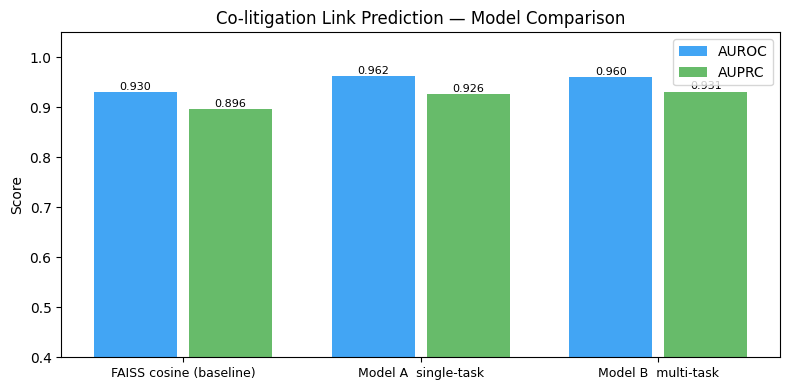

In [15]:
# Cell 14 — Comparison
import matplotlib.pyplot as plt

faiss_v, faiss_p = faiss_baseline_auc(test_edges)

results = [
    ('FAISS cosine (baseline)', faiss_v,   faiss_p),
    ('Model A  single-task',    te_auroc_A, te_auprc_A),
    ('Model B  multi-task',     te_auroc_B, te_auprc_B),
]

print('=' * 52)
print(f'{"Model":<28} {"AUROC":>7}  {"AUPRC":>7}')
print('-' * 52)
for name, auroc, auprc in results:
    print(f'{name:<28} {auroc:>7.4f}  {auprc:>7.4f}')
print('=' * 52)

fig, ax = plt.subplots(figsize=(8, 4))
names  = [r[0] for r in results]
aurocs = [r[1] for r in results]
auprc  = [r[2] for r in results]
x = np.arange(len(names))
ax.bar(x - 0.2, aurocs, 0.35, label='AUROC', color='#2196F3', alpha=0.85)
ax.bar(x + 0.2, auprc,  0.35, label='AUPRC', color='#4CAF50', alpha=0.85)
for i, (a, p) in enumerate(zip(aurocs, auprc)):
    ax.text(i - 0.2, a + 0.005, f'{a:.3f}', ha='center', fontsize=8)
    ax.text(i + 0.2, p + 0.005, f'{p:.3f}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=9)
ax.set_ylim(0.4, 1.05)
ax.set_ylabel('Score')
ax.set_title('Co-litigation Link Prediction — Model Comparison')
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
# Cell 15 — Embedding quality: within-case vs cross-case similarity
# Better embeddings: within-case P-D similarity > random P-D similarity

@torch.no_grad()
def embedding_quality(model, hetero_data, edges, label=''):
    model.eval()
    h = model(hetero_data)['patent'].cpu().numpy()

    # Positive: actual co-litigation pairs
    src_e = h[edges[0].numpy()]
    dst_e = h[edges[1].numpy()]
    pos_sim = (src_e * dst_e).sum(1) / (np.linalg.norm(src_e, axis=1) * np.linalg.norm(dst_e, axis=1) + 1e-8)

    # Negative: random pairs
    rng3 = np.random.default_rng(77)
    neg_idx = rng3.integers(0, h.shape[0], size=len(pos_sim))
    neg_e = h[neg_idx]
    neg_sim = (src_e * neg_e).sum(1) / (np.linalg.norm(src_e, axis=1) * np.linalg.norm(neg_e, axis=1) + 1e-8)

    print(f'{label}')
    print(f'  Co-litigation pairs : mean={pos_sim.mean():.4f}  std={pos_sim.std():.4f}')
    print(f'  Random pairs        : mean={neg_sim.mean():.4f}  std={neg_sim.std():.4f}')
    print(f'  Gap (pos - neg)     : {pos_sim.mean() - neg_sim.mean():.4f}')
    return pos_sim, neg_sim

te_e_cpu = test_edges
print('[FAISS baseline]')
faiss_h_mock = type('M', (), {'eval': lambda s: None})()
src_raw = pat_emb[te_e_cpu[0].numpy()]
dst_raw = pat_emb[te_e_cpu[1].numpy()]
rng4    = np.random.default_rng(77)
neg_raw = pat_emb[rng4.integers(0, len(pat_list), len(src_raw))]
pos_raw_sim = (src_raw * dst_raw).sum(1)
neg_raw_sim = (src_raw * neg_raw).sum(1)
print(f'  Co-litigation pairs : mean={pos_raw_sim.mean():.4f}')
print(f'  Random pairs        : mean={neg_raw_sim.mean():.4f}')
print(f'  Gap                 : {pos_raw_sim.mean()-neg_raw_sim.mean():.4f}')
print()
embedding_quality(modelA, data_d, te_e_cpu, '[Model A single-task]')
print()
embedding_quality(modelB, data_d, te_e_cpu, '[Model B multi-task]')

[FAISS baseline]
  Co-litigation pairs : mean=0.6675
  Random pairs        : mean=0.5101
  Gap                 : 0.1574

[Model A single-task]
  Co-litigation pairs : mean=0.9200  std=0.1186
  Random pairs        : mean=0.0660  std=0.2969
  Gap (pos - neg)     : 0.8539

[Model B multi-task]
  Co-litigation pairs : mean=0.9143  std=0.0659
  Random pairs        : mean=0.4697  std=0.2475
  Gap (pos - neg)     : 0.4446


(array([0.92739224, 0.8548551 , 0.94910026, 0.83455205, 0.8389148 ,
        0.8838747 , 0.95721644, 0.98292613, 0.9410387 , 0.9015986 ,
        0.9098881 , 0.932779  , 0.9738543 , 0.9508499 , 0.91826224,
        0.9318668 , 0.960606  , 0.93830365, 0.93699217, 0.9622685 ,
        0.95513886, 0.91536796, 0.91472834, 0.95861894, 0.9092298 ,
        0.9083716 , 0.9572891 , 0.9077769 , 0.9823207 , 0.8146581 ,
        0.76112556, 0.923099  , 0.9779478 , 0.9784261 , 0.9783555 ,
        0.9456501 , 0.9475367 , 0.95056343, 0.96712875, 0.96753156,
        0.9745002 , 0.9683834 , 0.95320076, 0.98522776, 0.98711663,
        0.98524076, 0.9874379 , 0.8957056 , 0.8948863 , 0.88952655,
        0.8886253 , 0.58229864, 0.9793437 , 0.9820126 , 0.96308964,
        0.97516996, 0.9100054 , 0.8861461 , 0.7927265 , 0.73445755,
        0.98703843, 0.9782467 , 0.93360645, 0.8483195 , 0.810562  ,
        0.90003073, 0.90637887, 0.8859574 , 0.79430336, 0.73556787,
        0.9872874 , 0.9071372 , 0.8858613 , 0.79